In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")   # lets the notebook import from src/

from src.data import load_all, FEATURES

df, X, scaler, km = load_all()
print(df.shape, X.shape)
print(df["cluster"].value_counts().sort_index().tolist())

(65416, 23) (65416, 7)
[3015, 22589, 18040, 14437, 7335]


In [3]:
from src.data import load_all
from src.matching import Library, build_playlist, DEFAULT_PLAN

df, X, scaler, km = load_all()
print(df.shape, X.shape)
print(df["cluster"].value_counts().sort_index().tolist())

lib = Library(df, X, scaler)

for s in [1, 2, 3, 4, 5]:
    pl = build_playlist(lib, DEFAULT_PLAN, 45, seed=s)
    print(s, len(pl), "tracks,", round(pl["duration_ms"].sum() / 60_000, 1), "min")

pl = build_playlist(lib, DEFAULT_PLAN, 45, seed=1)
pl[["phase", "track_name", "artists", "energy", "tempo", "distance"]]

(65416, 23) (65416, 7)
[3015, 22589, 18040, 14437, 7335]
1 13 tracks, 46.2 min
2 13 tracks, 47.5 min
3 14 tracks, 47.0 min
4 12 tracks, 43.6 min
5 13 tracks, 45.5 min


,phase,track_name,artists,energy,tempo,distance
0,warmup,Love Me Now (feat. Zoe Wees),Kygo;Zoe Wees,0.489,102.040,0.721475
1,warmup,Drown,Weston Estate,0.554,120.024,0.708083
2,warmup,Cloak & Dagger (feat. J Hus),Burna Boy;J Hus,0.601,103.748,0.723518
3,peak,Angel With a Shotgun,The Cab,0.840,124.037,0.643111
4,peak,愛人錯過,告五人,0.923,140.045,0.645179
5,peak,Halleluja,Rammstein,0.846,130.128,0.499553
6,peak,Call Me A Spaceman,Hardwell;Mitch Crown,0.878,127.945,0.654841
7,peak,Come Around Again,Armin van Buuren;Billen Ted;JC Stewart,0.912,123.946,0.658099
8,peak,Dónde está el amor (feat. Jesse & Joy),Pablo Alborán;Jesse & Joy,0.848,139.876,0.652419
9,peak,Feel My Love (feat. Joe Taylor),Lucas & Steve;DubVision;Joe Taylor,0.868,124.979,0.640771


In [4]:
from src.data import load_all
from src.matching import Library, build_playlist
from src.mood import MoodParser

df, X, scaler, km = load_all()
lib = Library(df, X, scaler)
parser = MoodParser(lib)

plan, fallback = parser.parse("feeling sluggish but need to hit a heavy leg day")
print("fallback used:", fallback)
for phase, vec in plan.items():
    print(phase, {k: round(v, 2) for k, v in vec.items()})

pl = build_playlist(lib, plan, 45, seed=1)
print(len(pl), "tracks,", round(pl["duration_ms"].sum() / 60_000, 1), "min")
print(pl.groupby("phase")["distance"].mean().round(2))

fallback used: False
warmup {'energy': 0.82, 'valence': 0.78, 'tempo': 120.0, 'danceability': 0.72, 'loudness': -5.5, 'acousticness': 0.1, 'instrumentalness': 0.0}
peak {'energy': 0.95, 'valence': 0.4, 'tempo': 125.0, 'danceability': 0.45, 'loudness': -3.5, 'acousticness': 0.01, 'instrumentalness': 0.0}
cooldown {'energy': 0.45, 'valence': 0.4, 'tempo': 105.0, 'danceability': 0.5, 'loudness': -9.0, 'acousticness': 0.75, 'instrumentalness': 0.05}
12 tracks, 44.5 min
phase
cooldown    0.84
peak        0.57
warmup      0.50
Name: distance, dtype: float64


In [7]:
from src.data import load_and_clean

df = load_and_clean()
print(df.shape)
print(df["year"].describe())
print(df["track_genre"].value_counts())
df[["track_name", "artists", "year", "popularity"]].sample(15, random_state=1)

c:\Users\prana\OneDrive\Desktop\Projects\pump-sync\notebooks\..\src\data.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  from sklearn.cluster import KMeans


(142406, 16)
count    142406.000000
mean       2013.230194
std           6.454031
min        2000.000000
25%        2008.000000
50%        2015.000000
75%        2019.000000
max        2025.000000
Name: year, dtype: float64
track_genre
Rock          41781
Electronic    22811
Pop           19299
Hip-Hop       17594
Country       12990
Folk          11910
R&B            8567
Classical      2512
Blues          2482
Jazz           2460
Name: count, dtype: int64


,track_name,artists,year,popularity
39447,Marching On Versailles,Ad Infinitum,2020,41
1061,Cold,Crossfade,2004,74
68293,ANYWHERE ANYTIME,george,2022,34
32205,But For The Grace Of God,Keith Urban,2007,44
134582,Down Without a Fight,zebrahead,2017,21
50892,Questions,Tamia,2004,38
85410,Candy Jail,Silver Jews,2008,30
93773,In My Arms,Mark Wills,2000,28
116020,"Think (From the Motion Picture ""What Men Want"")",H.E.R.,2019,24
19380,The Healer,Erykah Badu,2007,50


tracks with popularity >= 55: 12107
2 749684 0.288
3 617093 0.212
4 523911 0.23
5 475705 0.21
6 439239 0.194
7 414694 0.195
8 394315 0.181
9 377790 0.185
10 362722 0.179


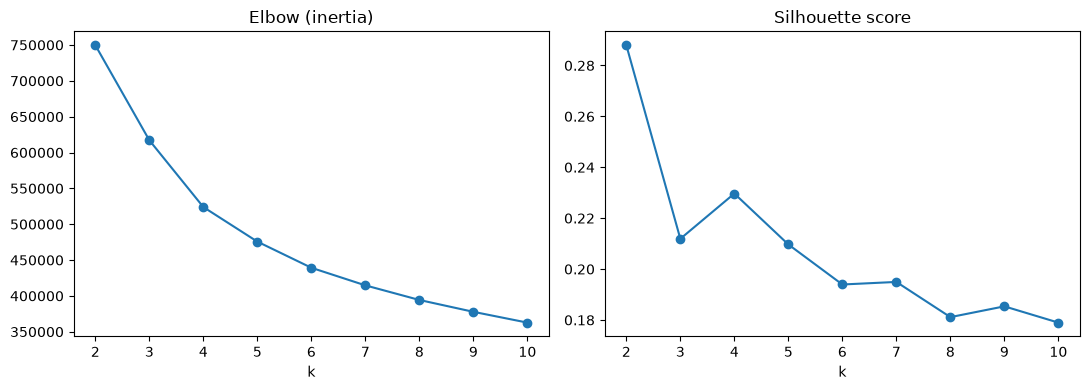

In [8]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from src.data import load_and_clean, FEATURES

df = load_and_clean()
print("tracks with popularity >= 55:", (df["popularity"] >= 55).sum())

X = StandardScaler().fit_transform(df[FEATURES])

K_RANGE = range(2, 11)
inertias, silhouettes = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=5, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels, sample_size=10000, random_state=42))
    print(k, round(inertias[-1]), round(silhouettes[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(K_RANGE), inertias, marker="o")
axes[0].set_title("Elbow (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(list(K_RANGE), silhouettes, marker="o")
axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [9]:
for k in [4, 5]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    d2 = df.copy()
    d2["cluster"] = km.fit_predict(X)
    profile = d2.groupby("cluster")[FEATURES].mean().round(2)
    profile["size"] = d2["cluster"].value_counts().sort_index()
    profile["popular"] = d2[d2["popularity"] >= 55]["cluster"].value_counts().sort_index()
    print(f"k={k}")
    display(profile)

k=4


,energy,valence,tempo,danceability,loudness,acousticness,instrumentalness,size,popular
cluster,,,,,,,,,
0,0.79,0.35,126.01,0.49,-6.95,0.10,0.71,11208,465
1,0.84,0.36,137.67,0.45,-4.97,0.05,0.03,49699,3549
2,0.36,0.34,113.93,0.52,-10.97,0.65,0.05,26473,2056
3,0.71,0.62,114.71,0.69,-6.27,0.16,0.02,55026,6037


k=5


,energy,valence,tempo,danceability,loudness,acousticness,instrumentalness,size,popular
cluster,,,,,,,,,
0,0.85,0.44,160.55,0.44,-4.90,0.06,0.02,28323,2091
1,0.78,0.32,108.22,0.52,-5.54,0.07,0.02,35050,2974
2,0.71,0.67,116.14,0.71,-6.35,0.17,0.02,43511,4695
3,0.35,0.34,114.27,0.52,-11.16,0.67,0.05,24583,1888
4,0.79,0.35,126.10,0.49,-6.96,0.10,0.71,10939,459


In [10]:
import pandas as pd
from sklearn.cluster import KMeans

km = KMeans(n_clusters=5, n_init=10, random_state=42)
df["cluster"] = km.fit_predict(X)

print(pd.crosstab(df["cluster"], df["track_genre"], normalize="index").round(2))

popular = df[df["popularity"] >= 55]
for c in range(5):
    print(f"--- cluster {c} ---")
    print(popular[popular["cluster"] == c][["track_name", "artists", "track_genre"]]
          .sample(8, random_state=1).to_string(index=False))

track_genre  Blues  Classical  Country  Electronic  Folk  Hip-Hop  Jazz   Pop  \
cluster                                                                         
0             0.01       0.01     0.08        0.14  0.04     0.07  0.00  0.12   
1             0.01       0.01     0.07        0.19  0.04     0.11  0.00  0.11   
2             0.02       0.01     0.10        0.16  0.11     0.23  0.01  0.16   
3             0.03       0.06     0.16        0.06  0.18     0.06  0.07  0.18   
4             0.01       0.01     0.01        0.34  0.02     0.01  0.01  0.07   

track_genre   R&B  Rock  
cluster                  
0            0.02  0.50  
1            0.04  0.43  
2            0.10  0.10  
3            0.08  0.11  
4            0.01  0.52  
--- cluster 0 ---
            track_name            artists track_genre
  Grinding All My Life      Nipsey Hussle     Hip-Hop
   Devil's Dance Floor     Flogging Molly        Rock
                Stitch           Wage War        Rock
A Favor House At

In [12]:
from src.data import load_all
from src.matching import Library, build_playlist
from src.mood import MoodParser

df, X, scaler, km = load_all()
lib = Library(df, X, scaler)
parser = MoodParser(lib)

plan, fallback = parser.parse("need to go hard on leg day")
print("fallback used:", fallback)

for restrict in [False, True]:
    p = build_playlist(lib, plan, 45, seed=1, include_genres=["Hip-Hop"],
                       restrict_to_phase_clusters=restrict)
    print("restricted:", restrict, "|", len(p), "tracks,",
          round(p["duration_ms"].sum() / 60_000, 1), "min |",
          p.groupby("phase")["distance"].mean().round(2).to_dict())

pl = build_playlist(lib, plan, 45, seed=1, include_genres=["Hip-Hop"])
pl[["phase", "track_name", "artists", "year", "energy", "tempo", "distance"]]

fallback used: False
restricted: False | 12 tracks, 44.8 min | {'cooldown': 1.63, 'peak': 0.82, 'warmup': 1.04}
restricted: True | 12 tracks, 46.6 min | {'cooldown': 1.63, 'peak': 0.82, 'warmup': 1.04}


,phase,track_name,artists,year,energy,tempo,distance
0,warmup,Two Words,"Kanye West, Mos Def, Freeway, The Boys Choir O...",2004,0.807,84.649,1.034775
1,warmup,6PM In New York,Drake,2015,0.850,128.429,1.040136
2,peak,"Ooh Wee (feat. Ghostface Killah, Nate Dogg, Tr...","Mark Ronson, Ghostface Killah, Nate Dogg, Trif...",2003,0.961,105.031,0.835051
3,peak,(When You Gonna) Give It Up to Me (feat. Keysh...,"Sean Paul, Keyshia Cole",2006,0.761,95.824,0.868002
4,peak,Butterfly,Crazy Town,2000,0.811,103.502,0.455865
5,peak,"SG (with Ozuna, Megan Thee Stallion & LISA of ...","DJ Snake, Ozuna, Megan Thee Stallion, LISA",2021,0.837,100.015,0.929945
6,peak,Crazy In Love (feat. JAY-Z),"Beyoncé, JAY-Z",2003,0.758,99.259,0.934688
7,peak,Simon Says,Pharoahe Monch,2019,0.913,92.222,0.890706
8,peak,"Ante Up Remix (feat. Busta Rhymes, Teflon & Re...","M.O.P., Busta Rhymes, Teflon, Remi Martin",2000,0.894,94.089,0.796782
9,cooldown,Hands On,"Kanye West, Fred Hammond",2019,0.393,78.039,1.678040


In [14]:
old = df[(df["track_genre"] == "Hip-Hop") & (df["year"] < 2000)]
for p in [40, 50, 55]:
    print(p, (old["popularity"] >= p).sum())

40 1094
50 478
55 293


In [19]:
from src.data import load_all
from src.matching import Library, build_playlist
from src.mood import MoodParser

df, X, scaler, km = load_all()   # should pass the check now
lib = Library(df, X, scaler)
parser = MoodParser(lib)

plan, fallback = parser.parse("need to go hard on leg day, old school rap")
print("fallback used:", fallback)

pl = build_playlist(lib, plan, 45, seed=1, include_genres=["Hip-Hop"])
print(len(pl), "tracks,", round(pl["duration_ms"].sum() / 60_000, 1), "min")
pl[["phase", "track_name", "artists", "year", "energy", "tempo", "distance"]]

fallback used: False
14 tracks, 47.7 min


,phase,track_name,artists,year,energy,tempo,distance
0,warmup,Dipset (Santana's Town),"Juelz Santana, Cam'ron",2003,0.739,79.977,0.752211
1,warmup,Don Life (feat. Lil Wayne),"Big Sean, Lil Wayne",2020,0.776,97.934,0.755694
2,warmup,Thief's Theme,Nas,2004,0.776,94.314,0.718873
3,peak,BB Poison,Death Grips,2016,0.897,131.749,0.885177
4,peak,nightmare,"nothing,nowhere.",2021,0.913,139.906,0.890383
5,peak,Brand New Guy (feat. ScHoolboy Q),"A$AP Rocky, ScHoolboy Q",2011,0.903,114.191,0.477680
6,peak,End of the World,FORGOTTENAGE,2021,0.911,120.016,0.907201
7,peak,Don't Take Days off (feat. Dubb),"Nipsey Hussle, Dubb",2013,0.931,123.961,0.917244
8,peak,Touch The Sky,"Kanye West, Lupe Fiasco",2005,0.846,98.560,0.894047
9,peak,Know Me (Feat. DEAN),"DPR LIVE, DEAN",2017,0.889,134.052,0.844225
